* R = Recency >> Customer ne last purchase kab ki?
* F = Frequency >> Customer kitni baar purchase karta hai?
* M = Monetary >> Customer kitna paisa spend karta hai?

## Step 1: Load Data

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(
    "Online Retail.xlsx"
)

df = df.drop_duplicates()

df = df.dropna(
    subset=["CustomerID"]
)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

df["Revenue"] = (
    df["Quantity"] *
    df["UnitPrice"]
)

## Step 2: Reference Date
Latest purchase date nikalte hain.

In [3]:
reference_date = (
    df["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

reference_date

Timestamp('2011-12-10 12:50:00')

## Step 3: Create RFM Table

In [4]:
rfm = df.groupby(
    "CustomerID"
).agg({

    "InvoiceDate":
    lambda x: (
        reference_date - x.max()
    ).days,

    "InvoiceNo":
    "nunique",

    "Revenue":
    "sum"

})

### Rename Columns

In [5]:
rfm.columns = [

    "Recency",

    "Frequency",

    "Monetary"
]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,2,0.00
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


## Step 4: RFM Scores
Recency Score

In [6]:
rfm["R_Score"] = pd.qcut(

    rfm["Recency"],

    5,

    labels=[5,4,3,2,1]

)

## Frequency Score

In [7]:
rfm["F_Score"] = pd.qcut(

    rfm["Frequency"]
    .rank(method="first"),

    5,

    labels=[1,2,3,4,5]

)

## Monetary Score

In [8]:
rfm["M_Score"] = pd.qcut(

    rfm["Monetary"],

    5,

    labels=[1,2,3,4,5]

)

## Step 5: Create RFM Score

In [9]:
rfm["RFM_Score"] = (

    rfm["R_Score"]
    .astype(str)

    +

    rfm["F_Score"]
    .astype(str)

    +

    rfm["M_Score"]
    .astype(str)

)

In [10]:
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,2,0.00,1,2,1,121
12347.0,2,7,4310.00,5,4,5,545
12348.0,75,4,1797.24,2,3,4,234
12349.0,19,1,1757.55,4,1,4,414
12350.0,310,1,334.40,1,1,2,112


## Step 6: Customer Segments

In [11]:
def customer_segment(row):

    if row["RFM_Score"] == "555":

        return "Champions"

    elif row["R_Score"] >= 4:

        return "Loyal Customers"

    elif row["M_Score"] >= 4:

        return "Big Spenders"

    else:

        return "Regular Customers"

In [12]:
rfm["Segment"] = rfm.apply(
    customer_segment,
    axis=1
)

## Check Segments

In [13]:
rfm["Segment"].value_counts()

Segment
Regular Customers    1925
Loyal Customers      1437
Big Spenders          667
Champions             343
Name: count, dtype: int64

### Visualization

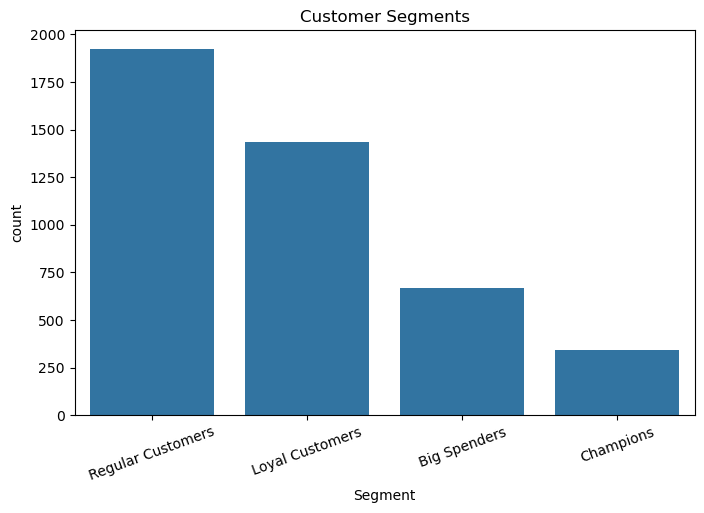

In [14]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=rfm,
    x="Segment"
)

plt.title(
    "Customer Segments"
)

plt.xticks(
    rotation=20
)

plt.show()

## Step 7: Segment Revenue

In [15]:
segment_revenue = (

    rfm.groupby(
        "Segment"
    )["Monetary"]

    .sum()

    .sort_values(
        ascending=False
    )

)

segment_revenue

Segment
Champions            3794607.990
Loyal Customers      2337045.060
Big Spenders         1480615.021
Regular Customers     666251.353
Name: Monetary, dtype: float64

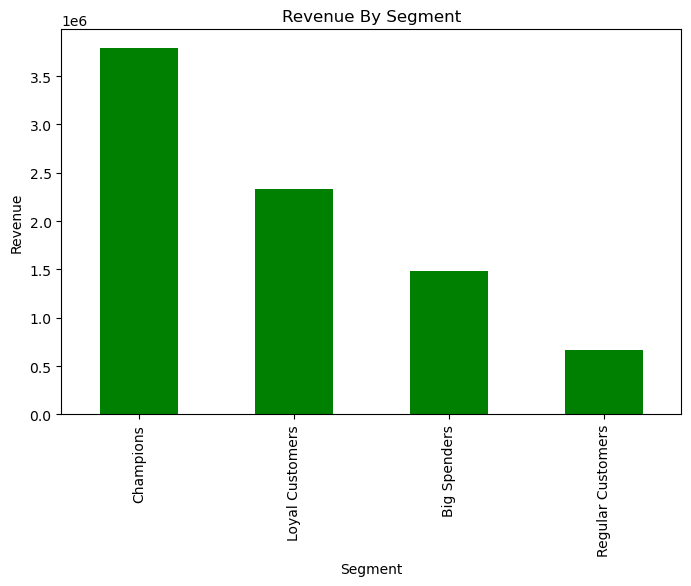

In [16]:
plt.figure(figsize=(8,5))

segment_revenue.plot(
    kind="bar",
    color="green"
)

plt.title(
    "Revenue By Segment"
)

plt.ylabel(
    "Revenue"
)

plt.show()

## Business Insights

### Champions

- Most valuable customers
- High frequency purchases
- High spending customers

### Loyal Customers

- Purchase frequently
- Strong customer retention potential

### Big Spenders

- Generate high revenue
- Important for premium campaigns

### Regular Customers

- Average purchase behavior
- Potential for targeted promotions